Step 1: The Setup (Hunting for Squeezes)

The bot uses Keltner Channels (KC 20, 2.0) to detect market quietness.
Long Setup: When the Upper Band is sloping downwards
 Volatility is decreasing, the spring is coiling for an upward pulse.
Short Setup: When the Lower Band is sloping upwards
 Compression before a downward drop.

Step 2: The Trap (Entry - Anticipating Breakout)

Unlike previous strategies using Ichimoku, this strategy uses Past Close Prices for pending orders.
Buy Stop: Placed at the HIGHEST CLOSE price of the last 30 hours.
Sell Stop: Placed at the LOWEST CLOSE price of the last 30 hours.
Note: Pending orders expire after 9 hours if not filled.

Step 3: The Escape (Exit - Aggressive)

Time Exit (Most Important):
4-Bar Rule: If 4 hours pass after execution and neither SL nor PT is hit
 CLOSE POSITION IMMEDIATELY.
Why? The logic filters "False Breakouts". If price breaks the 30-hour resistance but doesn't fly immediately, the momentum is weak. Do not hold stagnation.
Capital Protection:
Stop Loss: 2.3 x ATR(20) (Medium distance).
Profit Target: 3.6 x ATR(25) (High reward expectation).
Trailing Stop: 1.4 x ATR(200). (Uses a super-long ATR 200 period to make the trailing line move very slowly and smoothly, avoiding whipsaws from minor noise).

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 2.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.0/62.0 kB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 240.3/240.3 kB 9.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.9/3.9 MB 65.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.5/16.5 MB 102.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.9/10.9 MB 130.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.4/42.4 MB 17.7 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.2, but you have pandas 3.0.0 which is incompatible.
gradio 5.50.0 requires pandas<3.0,>=1.0, but you have pandas 3.0.0 which is incompatible.
bqplot 0.12.45 requires pandas<3.0.0,>=1.0.0, but you have pandas 3.0.0 which is incomp

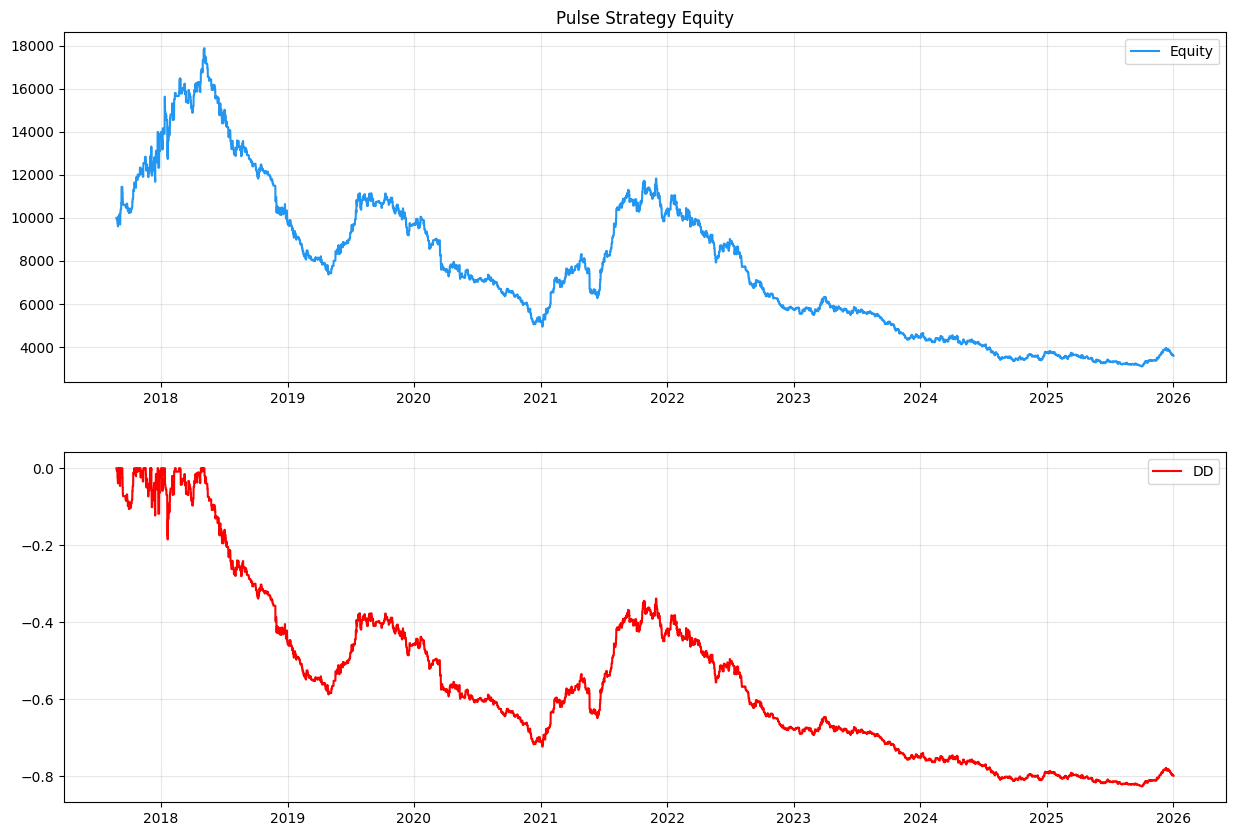

In [1]:
# ==============================================================================
# BƯỚC 1: CÀI ĐẶT THƯ VIỆN
# ==============================================================================
!pip install pandas_ta -q

import requests
import time
import pandas as pd
import pandas_ta as ta
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime

# ==============================================================================
# BƯỚC 2: CẤU HÌNH CHIẾN LƯỢC (Strategy: Pulse Breakout)
# ==============================================================================
CONFIG = {
    'SYMBOL': 'BTCUSDT',
    'INTERVAL': '1h',
    'START_DATE': '01/01/2015',
    'END_DATE': '31/12/2025',
    'INITIAL_CAPITAL': 10000.0,

    # --- Indicators ---
    'KC_PERIOD': 20,
    'KC_MULT': 2.0,          # Độ lệch chuẩn 2.0 (Khác chiến lược trước 2.3)
    'CHANNEL_PERIOD': 30,    # Chu kỳ tìm Highest/Lowest Close
    'SHIFT_LOOKBACK': 2,     # Lùi lại 2 nến để tính Channel

    'ATR_SL_PERIOD': 20,     # ATR tính SL
    'ATR_PT_PERIOD': 25,     # ATR tính PT
    'ATR_TRAIL_PERIOD': 200, # ATR tính Trailing (Siêu dài)

    # --- Entry & Management ---
    'SL_MULT': 2.3,          # 2.3 * ATR(20)
    'PT_MULT': 3.6,          # 3.6 * ATR(25)
    'TRAIL_MULT': 1.4,       # 1.4 * ATR(200)

    'ORDER_EXPIRATION': 9,   # Hủy lệnh sau 9 nến
    'TIME_EXIT_BARS': 4,     # Thoát sau 4 nến (Hit & Run)

    # Costs
    'FEE_RATE': 0.0004,      # 0.04%
    'SLIPPAGE': 0.0002       # 0.02%
}

# ==============================================================================
# BƯỚC 3: MODULE TẢI DỮ LIỆU (Giữ nguyên Template chuẩn)
# ==============================================================================
def str_to_millis(date_str: str) -> int:
    dt = datetime.strptime(date_str, "%d/%m/%Y")
    return int(dt.timestamp() * 1000)

def fetch_binance_kline_df(symbol: str, interval: str, start_str: str, end_str: str) -> pd.DataFrame:
    base_url = "https://data-api.binance.vision/"
    url = base_url + "api/v3/klines"
    req_symbol = symbol.upper()

    print(f"📡 Checking connection to Binance...")
    try:
        test = requests.get(f"{base_url}/api/v3/time", timeout=5)
        if test.status_code == 451:
            print("⚠️ US IP detected. Switching to Binance.US...")
            base_url = "https://api.binance.us"
            if req_symbol == "BTCUSDT":
                req_symbol = "BTCUSD"
    except:
        print("⚠️ Connection failed. Retrying with Binance.US...")
        base_url = "https://api.binance.us"
        req_symbol = "BTCUSD"

    url = base_url + "/api/v3/klines"
    start_time = str_to_millis(start_str)

    if end_str == datetime.now().strftime("%d/%m/%Y"):
        end_time = int(time.time() * 1000)
    else:
        end_dt = datetime.strptime(end_str, "%d/%m/%Y").replace(hour=23, minute=59, second=59)
        end_time = int(end_dt.timestamp() * 1000)

    all_klines = []
    print(f"⏳ Downloading {req_symbol} ({interval}) from {base_url}...")

    while start_time < end_time:
        params = {"symbol": req_symbol, "interval": interval, "startTime": start_time, "endTime": end_time, "limit": 1000}
        try:
            r = requests.get(url, params=params, timeout=10)
            if r.status_code != 200: break
            data = r.json()
            if not data: break
            all_klines.extend(data)
            start_time = data[-1][0] + 1
            if len(all_klines) % 5000 == 0:
                print(f"   -> Downloaded: {len(all_klines)} candles")
            time.sleep(0.05)
        except: break

    if not all_klines: return pd.DataFrame()

    df = pd.DataFrame(all_klines, columns=["timestamp", "Open", "High", "Low", "Close", "Volume", "CT", "QAV", "NT", "TBBV", "TBQV", "I"])
    df = df[["timestamp", "Open", "High", "Low", "Close", "Volume"]]
    df["timestamp"] = pd.to_datetime(df["timestamp"], unit="ms")
    df.set_index("timestamp", inplace=True)
    df = df.astype(float)
    print(f"✅ Total: {len(df)} candles.")
    return df

# ==============================================================================
# BƯỚC 4: BACKTEST ENGINE (Logic Pulse Trading)
# ==============================================================================
def run_strategy(df):
    print("⚙️ Calculating indicators & Running Pulse Strategy...")
    df = df.copy()
    c = CONFIG

    # --- A. INDICATORS ---
    # 1. ATRs riêng biệt
    df['ATR_SL']    = ta.atr(df['High'], df['Low'], df['Close'], length=c['ATR_SL_PERIOD'])
    df['ATR_PT']    = ta.atr(df['High'], df['Low'], df['Close'], length=c['ATR_PT_PERIOD'])
    df['ATR_Trail'] = ta.atr(df['High'], df['Low'], df['Close'], length=c['ATR_TRAIL_PERIOD'])

    # 2. Keltner Channels (Setup Filter)
    kc_basis = ta.ema(df['Close'], length=c['KC_PERIOD'])
    kc_range = ta.atr(df['High'], df['Low'], df['Close'], length=c['KC_PERIOD'])
    df['KC_Upper'] = kc_basis + (c['KC_MULT'] * kc_range)
    df['KC_Lower'] = kc_basis - (c['KC_MULT'] * kc_range)

    # 3. Price Channel (Highest/Lowest Close) - ENTRY SIGNAL
    # Shift 2: Tính toán dựa trên quá khứ cách đây 2 nến (để tránh repaint hoặc tín hiệu quá sớm)
    df['Highest_Close'] = df['Close'].shift(c['SHIFT_LOOKBACK']).rolling(c['CHANNEL_PERIOD']).max()
    df['Lowest_Close']  = df['Close'].shift(c['SHIFT_LOOKBACK']).rolling(c['CHANNEL_PERIOD']).min()

    df.dropna(inplace=True)

    # --- B. INITIALIZATION ---
    capital = c['INITIAL_CAPITAL']
    position = 0; entry_price = 0.0; entry_idx = 0
    sl_price = 0.0; tp_price = 0.0
    pending_orders = []; trades = []
    equity_curve = [c['INITIAL_CAPITAL']] * len(df)

    # Numpy Arrays
    opens = df['Open'].values; highs = df['High'].values; lows = df['Low'].values; closes = df['Close'].values
    times = df.index

    # Indicators Array
    atr_sl = df['ATR_SL'].values; atr_pt = df['ATR_PT'].values; atr_trail = df['ATR_Trail'].values
    kc_upper = df['KC_Upper'].values; kc_lower = df['KC_Lower'].values
    highest_close = df['Highest_Close'].values; lowest_close = df['Lowest_Close'].values

    # --- C. MAIN LOOP ---
    for i in range(1, len(df)):

        # 1. QUẢN LÝ LỆNH ĐANG CHẠY (EXIT)
        if position != 0:
            exit_signal = False; exit_reason = ""; raw_exit_price = closes[i]

            if position == 1:
                if lows[i] <= sl_price:
                    exit_signal = True; exit_reason = "SL Hit"; raw_exit_price = sl_price
                elif highs[i] >= tp_price:
                    exit_signal = True; exit_reason = "TP Hit"; raw_exit_price = tp_price
                elif (i - entry_idx) >= c['TIME_EXIT_BARS']: # Time Exit 4 nến
                    exit_signal = True; exit_reason = "Time Exit (4 Bars)"; raw_exit_price = closes[i]

            elif position == -1:
                if highs[i] >= sl_price:
                    exit_signal = True; exit_reason = "SL Hit"; raw_exit_price = sl_price
                elif lows[i] <= tp_price:
                    exit_signal = True; exit_reason = "TP Hit"; raw_exit_price = tp_price
                elif (i - entry_idx) >= c['TIME_EXIT_BARS']: # Time Exit 4 nến
                    exit_signal = True; exit_reason = "Time Exit (4 Bars)"; raw_exit_price = closes[i]

            if exit_signal:
                # Tính PnL
                if position == 1:
                    real_exit = min(opens[i], raw_exit_price) if "SL" in exit_reason else raw_exit_price
                    real_exit *= (1 - c['SLIPPAGE'])
                    pnl = (real_exit - entry_price) / entry_price
                else:
                    real_exit = max(opens[i], raw_exit_price) if "SL" in exit_reason else raw_exit_price
                    real_exit *= (1 + c['SLIPPAGE'])
                    pnl = (entry_price - real_exit) / entry_price

                net_pnl = pnl - (c['FEE_RATE'] * 2)
                capital += (capital * net_pnl) # Compounding

                trades.append({'Date': times[i], 'Type': 'Long' if position == 1 else 'Short', 'Reason': exit_reason, 'PnL': capital * net_pnl, 'Equity': capital})
                position = 0; pending_orders = []

            else:
                # Trailing Stop (ATR 200 - Chậm & Chắc)
                if position == 1:
                    new_sl = closes[i] - (c['TRAIL_MULT'] * atr_trail[i])
                    if new_sl > sl_price: sl_price = new_sl
                elif position == -1:
                    new_sl = closes[i] + (c['TRAIL_MULT'] * atr_trail[i])
                    if new_sl < sl_price: sl_price = new_sl

        # 2. XỬ LÝ LỆNH CHỜ (ENTRY)
        if position == 0:
            # Lọc lệnh hết hạn (9 nến)
            pending_orders = [o for o in pending_orders if (i - o['created_idx']) < c['ORDER_EXPIRATION']]

            triggered = None
            for order in pending_orders:
                if order['type'] == 'buy' and highs[i] >= order['price']:
                    triggered = order; exec_price = max(opens[i], order['price']) if opens[i] > order['price'] else order['price']
                    break
                elif order['type'] == 'sell' and lows[i] <= order['price']:
                    triggered = order; exec_price = min(opens[i], order['price']) if opens[i] < order['price'] else order['price']
                    break

            if triggered:
                entry_idx = i
                if triggered['type'] == 'buy':
                    position = 1
                    entry_price = exec_price * (1 + c['SLIPPAGE'])
                    # SL tính theo ATR(20), PT tính theo ATR(25)
                    sl_price = exec_price - (c['SL_MULT'] * atr_sl[i])
                    tp_price = exec_price + (c['PT_MULT'] * atr_pt[i])
                else:
                    position = -1
                    entry_price = exec_price * (1 - c['SLIPPAGE'])
                    sl_price = exec_price + (c['SL_MULT'] * atr_sl[i])
                    tp_price = exec_price - (c['PT_MULT'] * atr_pt[i])

                pending_orders = []

        # 3. TẠO TÍN HIỆU MỚI (LOGIC CHIẾN LƯỢC MỚI)
        if position == 0:
            # Setup Long: Upper Band chúc xuống (Squeeze)
            setup_long = kc_upper[i] < kc_upper[i-1]
            # Setup Short: Lower Band chúc lên (Squeeze)
            setup_short = kc_lower[i] > kc_lower[i-1]

            # Entry Price: Highest/Lowest Close 30 nến (đã shift 2)
            buy_entry_price = highest_close[i]
            sell_entry_price = lowest_close[i]

            if setup_long:
                pending_orders.append({'type': 'buy', 'price': buy_entry_price, 'created_idx': i})

            if setup_short and not setup_long:
                pending_orders.append({'type': 'sell', 'price': sell_entry_price, 'created_idx': i})

        equity_curve[i] = capital

    return pd.Series(equity_curve, index=df.index), pd.DataFrame(trades)

# ==============================================================================
# BƯỚC 5: RUN & REPORT
# ==============================================================================
if __name__ == "__main__":
    df = fetch_binance_kline_df(CONFIG['SYMBOL'], CONFIG['INTERVAL'], CONFIG['START_DATE'], CONFIG['END_DATE'])

    if not df.empty:
        equity, trades_df = run_strategy(df)

        if not trades_df.empty:
            final_equity = equity.iloc[-1]
            total_return = (final_equity - CONFIG['INITIAL_CAPITAL']) / CONFIG['INITIAL_CAPITAL']

            rolling_max = equity.cummax()
            dd = (equity - rolling_max) / rolling_max
            max_dd = dd.min()

            wins = trades_df[trades_df['PnL'] > 0]
            losses = trades_df[trades_df['PnL'] <= 0]
            winrate = len(wins) / len(trades_df) if len(trades_df) > 0 else 0

            gross_profit = wins['PnL'].sum(); gross_loss = abs(losses['PnL'].sum())
            profit_factor = gross_profit / gross_loss if gross_loss != 0 else 0

            days = (equity.index[-1] - equity.index[0]).days
            cagr = ((final_equity / CONFIG['INITIAL_CAPITAL']) ** (365.0 / days)) - 1 if days > 0 else 0

            returns = equity.pct_change().dropna()
            sharpe_ratio = (returns.mean() / returns.std()) * np.sqrt(365 * 24) if returns.std() != 0 else 0

            print(f"\n{'='*30}")
            print(f"📊 BACKTEST RESULTS: {CONFIG['SYMBOL']}")
            print(f"{'='*30}")
            print(f"{'Final Equity:':>15} {final_equity:,.2f}")
            print(f"{'Total Return:':>15} {total_return:.2%}")
            print(f"{'CAGR (approx):':>15} {cagr:.2%}")
            print(f"{'Max Drawdown:':>15} {max_dd:.2%}")
            print(f"{'Sharpe Ratio:':>15} {sharpe_ratio:.2f}")
            print(f"{'Trades:':>15} {len(trades_df)}")
            print(f"{'Winrate:':>15} {winrate:.2%}")
            print(f"{'Profit Factor:':>15} {profit_factor:.2f}")
            print(f"{'='*30}")

            plt.figure(figsize=(15, 10))
            plt.subplot(2, 1, 1)
            plt.plot(equity, label='Equity', color='#2196F3'); plt.grid(True, alpha=0.3); plt.legend()
            plt.title('Pulse Strategy Equity')
            plt.subplot(2, 1, 2)
            plt.plot(dd, label='DD', color='red'); plt.grid(True, alpha=0.3); plt.legend()
            plt.show()
        else:
            print("⚠️ No trades executed.")
    else:
        print("❌ No data.")